Predict future averge price of Oils and Fats monthly by using SARIMAX model and Linear Regression Model
* According to the result, SARIMAX is better. But we can't tell exactly because of the causes of Covid 19 and Political changes.

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2009-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DOFM = data.copy()
DOFM = DOFM[DOFM['category']=='oil and fats']
DOFM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
15,1/15/2008,Rakhine,Maungdaw,Alel Than Kyaw,oil and fats,Oil (palm),palm,NaN,L,actual,Retail,MMK,2000.0,1.1236
18,1/15/2008,Rakhine,Maungdaw,Buthidaung,oil and fats,Oil (palm),palm,NaN,L,actual,Retail,MMK,2000.0,1.1236
21,1/15/2008,Rakhine,Maungdaw,Kyein Chung,oil and fats,Oil (palm),palm,NaN,L,actual,Retail,MMK,2000.0,1.1236
24,1/15/2008,Rakhine,Maungdaw,Maungdaw,oil and fats,Oil (palm),palm,NaN,L,actual,Retail,MMK,1950.0,1.0955
27,1/15/2008,Rakhine,Maungdaw,Myin Hlut,oil and fats,Oil (palm),palm,NaN,L,actual,Retail,MMK,1600.0,0.8989


In [13]:
DOFM = DOFM[['date', 'price']]
DOFM['date'] = pd.to_datetime(DOFM['date'])
mask = (DOFM['date']>=obv_st_date) & (DOFM['date']<=obv_end_date)
DOFM = DOFM.loc[mask]
DOFM = DOFM.set_index('date')
DOFM.head()

,price
date,
2008-01-15,2000.0
2008-01-15,2000.0
2008-01-15,2000.0
2008-01-15,1950.0
2008-01-15,1600.0


In [14]:
DOFM = DOFM.resample('MS').mean()
DOFM.head()

,price
date,
2008-01-01,1979.836923
2008-02-01,2197.552308
2008-03-01,2211.887692
2008-04-01,2084.195385
2008-05-01,2173.426154


In [15]:
DOFM.shape

(169, 1)

In [16]:
price = DOFM['price']
date = DOFM.index

##### Normalization data

In [17]:
scaler = MinMaxScaler()

In [18]:
DOFM_nor = scaler.fit_transform(DOFM)
DOFM_nor = pd.DataFrame(DOFM_nor)
DOFM_nor.head()

,0
0,0.280774
1,0.385244
2,0.392123
3,0.330850
4,0.373667


In [19]:
DOFM_nor['date']=date
DOFM_nor = DOFM_nor.set_index('date')
DOFM_nor.columns=['price']
DOFM_nor.head()

,price
date,
2008-01-01,0.280774
2008-02-01,0.385244
2008-03-01,0.392123
2008-04-01,0.330850
2008-05-01,0.373667


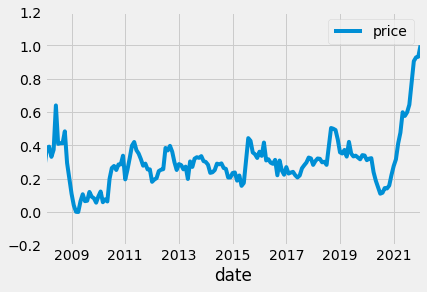

In [20]:
DOFM_nor.plot(grid=True)
plt.show()

It has no trend.

##### Checking Random Walk

In [21]:
RW_DOFM= adfuller(DOFM_nor)
RW_DOFM[1] # print P-value. If p-value<5%, reject null hypothesis

0.8963400382380136

<span style="color:red">Are there any external factors that may influence this price?</span>

##### Plotting ACF and PACF

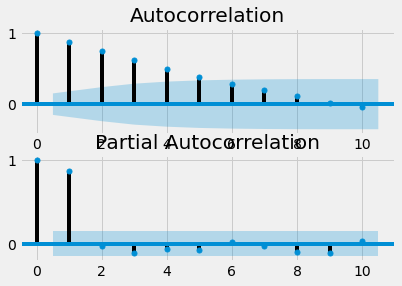

In [22]:
fig, axes=plt.subplots(2,1)
plot_acf(DOFM_nor, lags=10, ax=axes[0])
plot_pacf(DOFM_nor, lags=10, ax=axes[1])
plt.show()

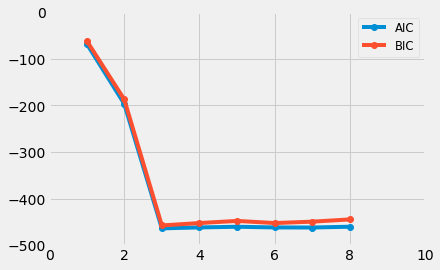

In [23]:
AIC, BIC = AIC_BIC_withOrderRange(DOFM_nor, p=3, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(1,0,0), 4:(1,0,1), 5:(1,0,2), 6:(2,0,0), 7:(2,0,1), 8:(2,0,2)

In [24]:
AIC, BIC

(array([ 117.28997367,  -67.66994253, -196.64933958, -463.68681587,
        -461.70127774, -460.26206238, -461.70320993, -461.86069301,
        -460.20721174]),
 array([ 120.41987239,  -61.4101451 , -187.25964344, -457.42701844,
        -452.3115816 , -447.74246752, -452.31351378, -449.34109815,
        -444.55771816]))

We will run again 3:(1,0,0), 4:(1,0,1), 5:(1,0,2), 6:(2,0,0), 7:(2,0,1), 8:(2,0,2)

In [25]:
mod_orders = [
    (1,0,0),
    (1,0,1),
    (1,0,2),
    (2,0,0),
    (2,0,1),
    (2,0,2)
]

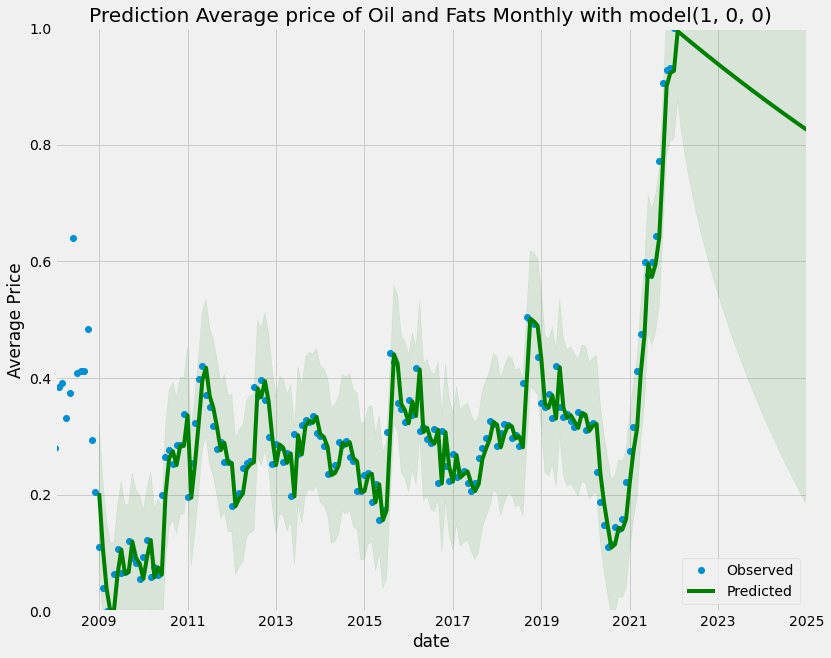

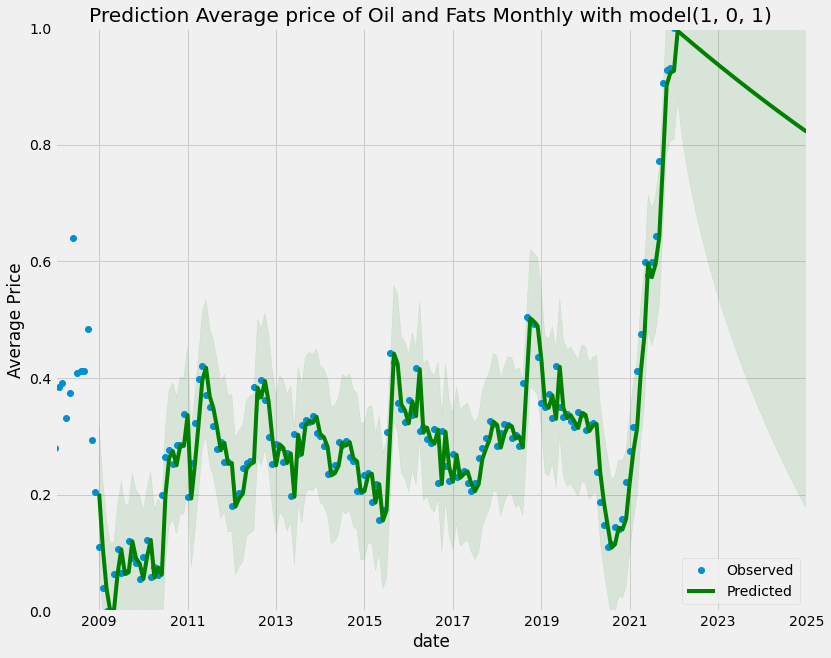

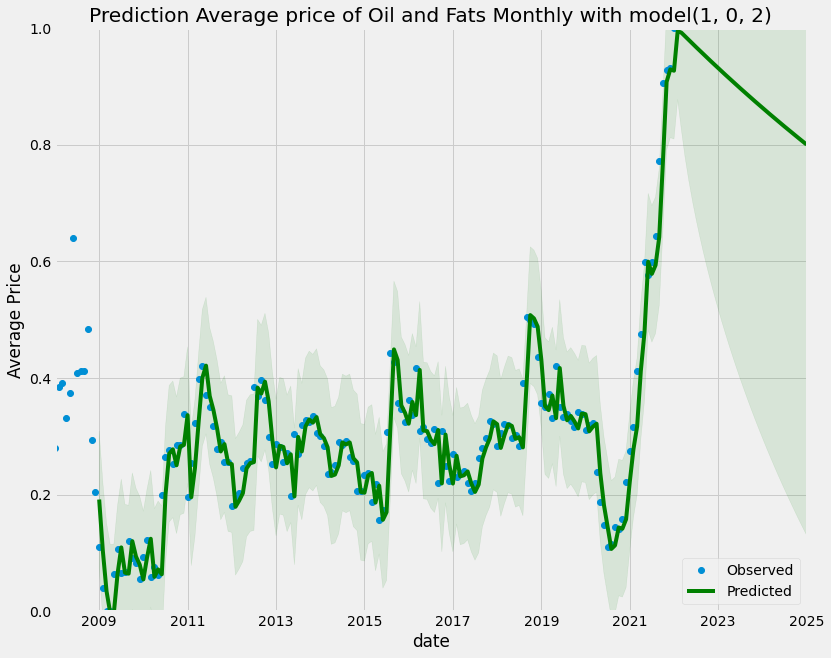

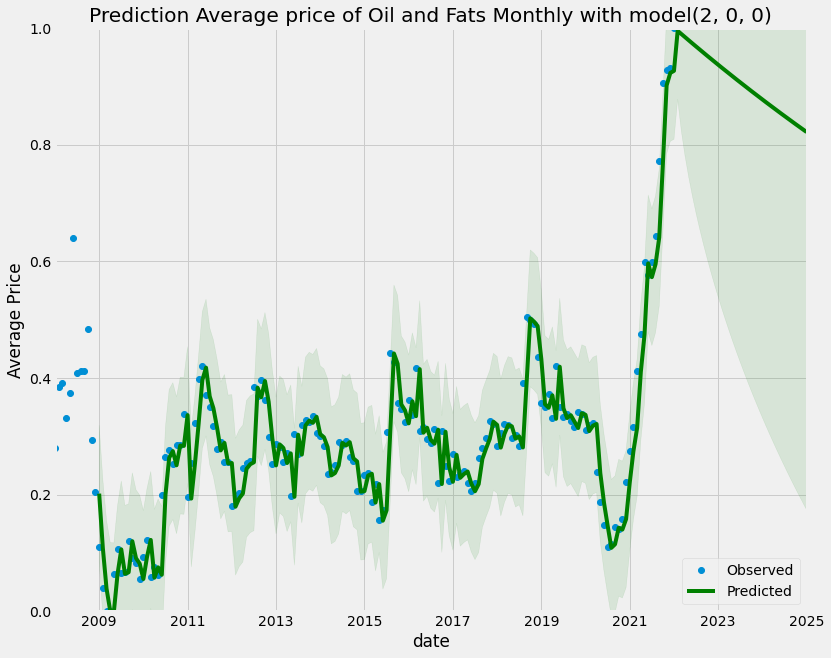

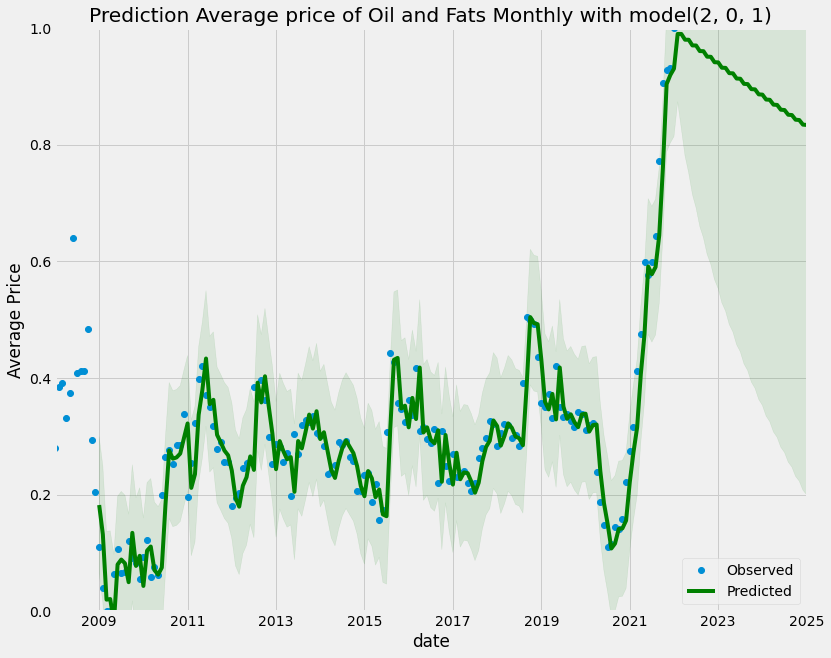

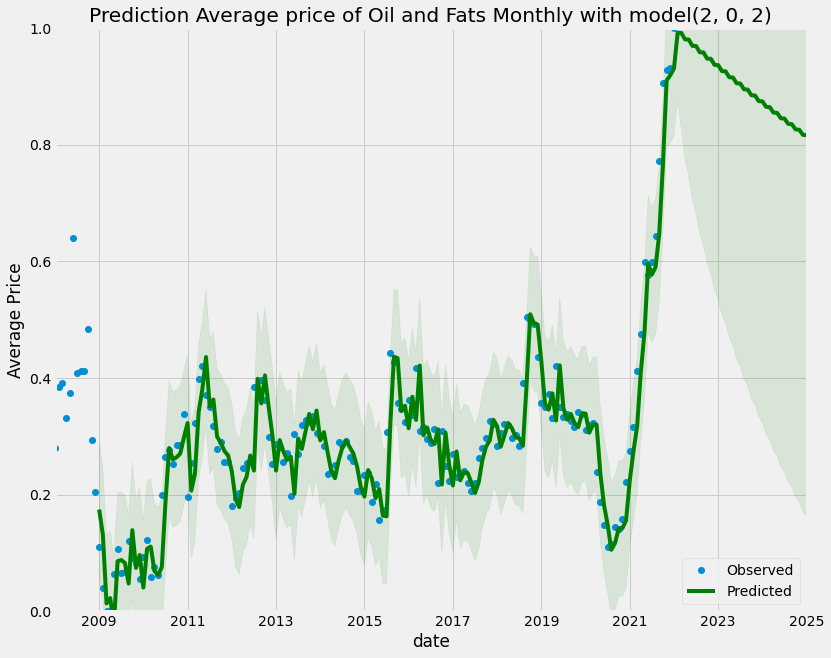

In [26]:
DOFM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DOFM_nor, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Oil and Fats Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DOFM_models.append(model)

Now we choose (1,0,0)

In [27]:
DOFM_model = DOFM_models[0]

In [28]:
DOFM_pred_normalized = DOFM_model.predict(pred_st_date, pred_end_date)
DOFM_pred_normalized

2009-01-01    2.026832e-01
2009-02-01    1.091596e-01
2009-03-01    3.954782e-02
2009-04-01    1.035735e-03
2009-05-01    1.354343e-21
                  ...     
2024-09-01    8.434563e-01
2024-10-01    8.389809e-01
2024-11-01    8.345292e-01
2024-12-01    8.301011e-01
2025-01-01    8.256965e-01
Freq: MS, Length: 193, dtype: float64

In [29]:
mask = (DOFM_nor.index>=pred_st_date) & (DOFM_nor.index<=pred_end_date)
DOFM_pred = DOFM_nor.loc[mask]
DOFM_pred

,price
date,
2009-01-01,0.109742
2009-02-01,0.039759
2009-03-01,0.001041
2009-04-01,0.000000
2009-05-01,0.064115
...,...
2021-09-01,0.771590
2021-10-01,0.905200
2021-11-01,0.927898


We need to un-normalized the predicted value to get actual price

In [30]:
pred_date = DOFM_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2009-01-01', '2009-02-01', '2009-03-01', '2009-04-01',
               '2009-05-01', '2009-06-01', '2009-07-01', '2009-08-01',
               '2009-09-01', '2009-10-01',
               ...
               '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01',
               '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01',
               '2024-11-01', '2024-12-01'],
              dtype='datetime64[ns]', length=192, freq='MS')

In [31]:
DOFM_pred_normalized_df = pd.DataFrame(DOFM_pred_normalized)
DOFM_pred_normalized_df = DOFM_pred_normalized_df[:-1] # the last index doesn't need
DOFM_pred_normalized_df

,0
2009-01-01,2.026832e-01
2009-02-01,1.091596e-01
2009-03-01,3.954782e-02
2009-04-01,1.035735e-03
2009-05-01,1.354343e-21
...,...
2024-08-01,8.479557e-01
2024-09-01,8.434563e-01
2024-10-01,8.389809e-01
2024-11-01,8.345292e-01


##### Un-normalization data

In [32]:
DOFM_pred_act = scaler.inverse_transform(DOFM_pred_normalized_df)
DOFM_pred_act_df = pd.DataFrame(DOFM_pred_act)
DOFM_pred_act_df['date'] = pred_date
DOFM_pred_act_df.columns = ['Predicted Price', 'date']
DOFM_pred_act_df.set_index('date',  inplace=True)
DOFM_pred_act_df

,Predicted Price
date,
2009-01-01,1817.093702
2009-02-01,1622.189334
2009-03-01,1477.117491
2009-04-01,1396.857819
2009-05-01,1394.699333
...,...
2024-08-01,3161.849673
2024-09-01,3152.473005
2024-10-01,3143.146090


In [33]:
mask = (DOFM.index>=pred_st_date) & (DOFM.index<=pred_end_date)
DOFM_Act = DOFM.loc[mask]
DOFM_Act

,price
date,
2009-01-01,1623.402857
2009-02-01,1477.557143
2009-03-01,1396.869333
2009-04-01,1394.699333
2009-05-01,1528.316667
...,...
2021-09-01,3002.702674
2021-10-01,3281.146739
2021-11-01,3328.451379


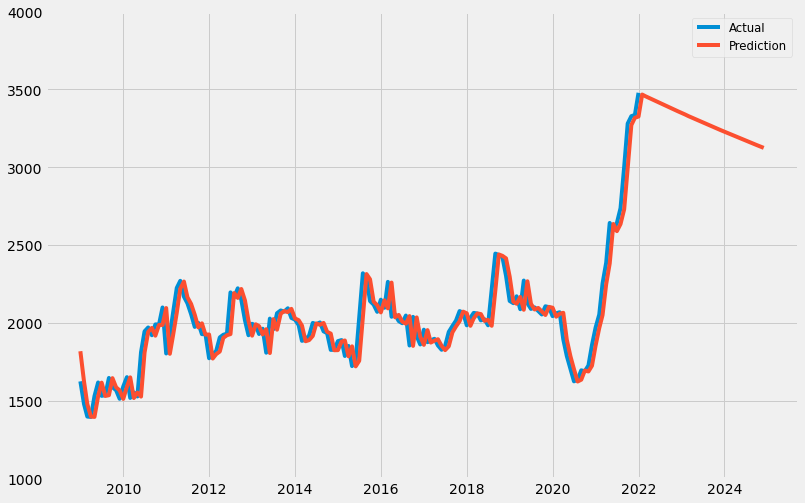

In [34]:
plt.figure(figsize=(12,8))
plt.plot(DOFM_Act, label="Actual")
plt.plot(DOFM_pred_act_df, label = "Prediction")
plt.legend(loc='best',fontsize='small')
plt.show()

### Linear Regression

In [35]:
temp_df = DOFM_nor.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2008-01-01,0.280774
1,2008-02-01,0.385244
2,2008-03-01,0.392123
3,2008-04-01,0.330850
4,2008-05-01,0.373667
...,...,...
164,2021-09-01,0.771590
165,2021-10-01,0.905200
166,2021-11-01,0.927898
167,2021-12-01,0.931724


In [36]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.8
train = temp_df[mask]
test = temp_df[~mask]
train, test

(          date     price                 time
 0   2008-01-01  0.280774  1199145600000000000
 1   2008-02-01  0.385244  1201824000000000000
 2   2008-03-01  0.392123  1204329600000000000
 3   2008-04-01  0.330850  1207008000000000000
 5   2008-06-01  0.639425  1212278400000000000
 ..         ...       ...                  ...
 162 2021-07-01  0.598300  1625097600000000000
 163 2021-08-01  0.644089  1627776000000000000
 164 2021-09-01  0.771590  1630454400000000000
 165 2021-10-01  0.905200  1633046400000000000
 167 2021-12-01  0.931724  1638316800000000000
 
 [136 rows x 3 columns],
           date     price                 time
 4   2008-05-01  0.373667  1209600000000000000
 10  2008-11-01  0.294308  1225497600000000000
 11  2008-12-01  0.203764  1228089600000000000
 19  2009-08-01  0.067309  1249084800000000000
 24  2010-01-01  0.093796  1262304000000000000
 31  2010-08-01  0.276049  1280620800000000000
 40  2011-05-01  0.419903  1304208000000000000
 45  2011-10-01  0.290227  131742

In [37]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1199145600000000000],
        [1201824000000000000],
        [1204329600000000000],
        [1207008000000000000],
        [1212278400000000000],
        [1214870400000000000],
        [1217548800000000000],
        [1220227200000000000],
        [1222819200000000000],
        [1230768000000000000]], dtype=int64),
 array([0.28077449, 0.38524382, 0.39212256, 0.33085023, 0.63942543,
        0.40873253, 0.41253547, 0.41264731, 0.48384096, 0.10974191]))

In [38]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1209600000000000000],
        [1225497600000000000],
        [1228089600000000000],
        [1249084800000000000],
        [1262304000000000000],
        [1280620800000000000],
        [1304208000000000000],
        [1317427200000000000],
        [1343779200000000000],
        [1349049600000000000]], dtype=int64),
 array([0.37366704, 0.2943083 , 0.2037644 , 0.06730925, 0.09379608,
        0.27604871, 0.41990341, 0.29022747, 0.36915458, 0.36149045]))

In [39]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [40]:
DOFM_linreg = LinearRegression().fit(X_train, y_train)

In [41]:
print('linear model coeff or slope (w): {}'.format(DOFM_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DOFM_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DOFM_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DOFM_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [4.70686916e-19]
linear model intercept (b): -0.370
R-squared score (training): 0.159
R-squared score (test): 0.168


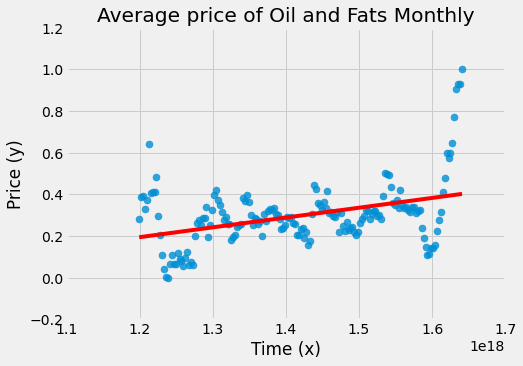

In [42]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DOFM_linreg.coef_ * X + DOFM_linreg.intercept_, 'r-')
plt.title('Average price of Oil and Fats Monthly')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [43]:
DOFM_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='MS').to_pydatetime().tolist(), columns=['date'])
DOFM_linear_predict['time'] = DOFM_linear_predict['date'].apply(lambda x: x.value)
DOFM_linear_predict

,date,time
0,2009-01-01,1230768000000000000
1,2009-02-01,1233446400000000000
2,2009-03-01,1235865600000000000
3,2009-04-01,1238544000000000000
4,2009-05-01,1241136000000000000
...,...,...
188,2024-09-01,1725148800000000000
189,2024-10-01,1727740800000000000
190,2024-11-01,1730419200000000000
191,2024-12-01,1733011200000000000


In [44]:
time_predict = np.array(DOFM_linear_predict['time']).reshape((-1, 1))
DOFM_linear_predict['price'] = DOFM_linreg.predict(time_predict)
DOFM_linear_predict

,date,time,price
0,2009-01-01,1230768000000000000,0.208914
1,2009-02-01,1233446400000000000,0.210174
2,2009-03-01,1235865600000000000,0.211313
3,2009-04-01,1238544000000000000,0.212574
4,2009-05-01,1241136000000000000,0.213794
...,...,...,...
188,2024-09-01,1725148800000000000,0.441612
189,2024-10-01,1727740800000000000,0.442832
190,2024-11-01,1730419200000000000,0.444093
191,2024-12-01,1733011200000000000,0.445313


In [45]:
DOFM_linear_normalized_predict = DOFM_linear_predict.copy()
DOFM_linear_normalized_predict = DOFM_linear_normalized_predict[['date', 'price']]
DOFM_linear_normalized_predict.set_index('date', inplace=True)
DOFM_linear_normalized_predict

,price
date,
2009-01-01,0.208914
2009-02-01,0.210174
2009-03-01,0.211313
2009-04-01,0.212574
2009-05-01,0.213794
...,...
2024-09-01,0.441612
2024-10-01,0.442832
2024-11-01,0.444093


##### Unnormalized the data

##### The Prediction Average Price of Oil and Fats Per KG using Linear Regression

In [46]:
DOFM_pred_act_KG_linear = scaler.inverse_transform(DOFM_linear_normalized_predict)
DOFM_pred_act_KG_linear_df = pd.DataFrame(DOFM_pred_act_KG_linear)
DOFM_pred_act_KG_linear_df['date'] = DOFM_linear_predict['date']
DOFM_pred_act_KG_linear_df.columns = ['Predicted Price (KG)', 'date']
DOFM_pred_act_KG_linear_df.set_index('date', inplace=True)
DOFM_pred_act_KG_linear_df

,Predicted Price (KG)
date,
2009-01-01,1830.077932
2009-02-01,1832.705222
2009-03-01,1835.078257
2009-04-01,1837.705547
2009-05-01,1840.248085
...,...
2024-09-01,2315.024698
2024-10-01,2317.567236
2024-11-01,2320.194526


##### The Prediction Average Price of Oil and Fats Per Viss using Linear Regression

1 Viss = 1.63293 KG

In [47]:
DOFM_pred_act_Viss_linear_df = DOFM_pred_act_KG_linear_df.copy()
DOFM_pred_act_Viss_linear_df.columns = ['Predicted Price (Viss)']
DOFM_pred_act_Viss_linear_df['Predicted Price (Viss)'] = DOFM_pred_act_Viss_linear_df['Predicted Price (Viss)'] * 1.63293
DOFM_pred_act_Viss_linear_df

,Predicted Price (Viss)
date,
2009-01-01,2988.389158
2009-02-01,2992.679338
2009-03-01,2996.554338
2009-04-01,3000.844518
2009-05-01,3004.996305
...,...
2024-09-01,3780.273280
2024-10-01,3784.425067
2024-11-01,3788.715247
